In [33]:
import numpy as np 
import tensorflow as tf 
import matplotlib.pyplot as plt
from tensorflow.keras import models, layers

In [34]:
x_train=np.load("x_train.npy")
y_train=np.load("y_train.npy")
x_test=np.load("x_test.npy") 
y_test=np.load("y_test.npy")

x_train=x_train/255.0
x_test=x_test/255.0

In [35]:
model=models.Sequential([
    layers.Input(shape=(32,32,3)),
    layers.Conv2D(32,(3,3),activation="relu"),
    tf.keras.layers.BatchNormalization(), 
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25), 

    layers.Conv2D(64,(3,3),activation="relu"),
    tf.keras.layers.BatchNormalization(), 
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Dropout(0.25), 

    layers.Conv2D(64,(3,3),activation="relu"),
    tf.keras.layers.BatchNormalization(), 

    layers.Flatten(),
    layers.Dense(64,activation="relu"),
    layers.Dense(10, activation='softmax')
])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 13, 13, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 123,210 (481.29 KB)

 Trainable params: 122,890 (480.04 KB)

 Non-trainable params: 320 (1.25 KB)

In [36]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
             loss="sparse_categorical_crossentropy",
              metrics=["accuracy"]
             )
history=model.fit(x_train,y_train,epochs=15,validation_split=0.1)


Epoch 1/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 34s 22ms/step - accuracy: 0.4758 - loss: 1.4785 - val_accuracy: 0.5800 - val_loss: 1.1899
Epoch 2/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 33s 23ms/step - accuracy: 0.6032 - loss: 1.1132 - val_accuracy: 0.5942 - val_loss: 1.1771
Epoch 3/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 36s 26ms/step - accuracy: 0.6604 - loss: 0.9659 - val_accuracy: 0.6266 - val_loss: 1.1128
Epoch 4/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 36s 25ms/step - accuracy: 0.6947 - loss: 0.8703 - val_accuracy: 0.6494 - val_loss: 1.0301
Epoch 5/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 30s 21ms/step - accuracy: 0.7163 - loss: 0.8003 - val_accuracy: 0.6948 - val_loss: 0.8814
Epoch 6/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 31s 22ms/step - accuracy: 0.7347 - loss: 0.7449 - val_accuracy: 0.7136 - val_loss: 0.8486
Epoch 7/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 31s 22ms/step - accuracy: 0.7525 - loss: 0.6989 - val_accuracy: 0.6802 - val_loss: 0.9592
Epoch 8/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 30s 22ms/step - accuracy: 0.7652 -

In [37]:
train_loss,train_acc=model.evaluate(x_train,y_train)
test_loss,test_acc=model.evaluate(x_test,y_test) 

print("Training Accuracy:", train_acc * 100, "%")
print("Training Loss:", train_loss)

print("Testing Accuracy:", test_acc * 100, "%")
print("Testing Loss:", test_loss)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8416 - loss: 0.4612
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7216 - loss: 0.9234
Training Accuracy: 84.16200280189514 %
Training Loss: 0.46122685074806213
Testing Accuracy: 72.15999960899353 %
Testing Loss: 0.923353910446167


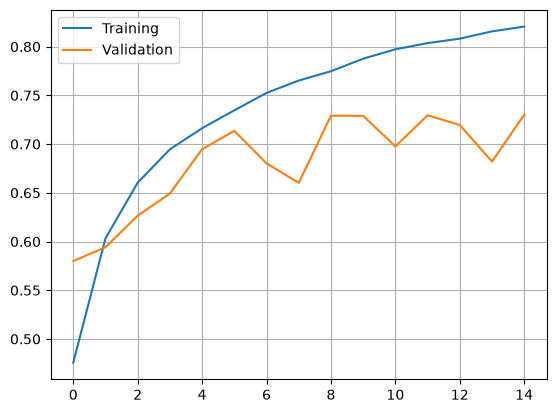

In [38]:
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.legend()
plt.grid()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


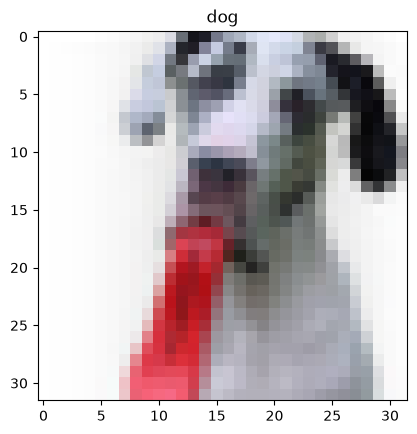

In [51]:
n = np.random.randint(0, len(x_test))

# Display the test image
plt.imshow(x_test[n])

# Predict the class
prediction = model.predict(x_test[n:n+1])

predicted_class = class_names[np.argmax(prediction)]

plt.title(predicted_class)
plt.show()


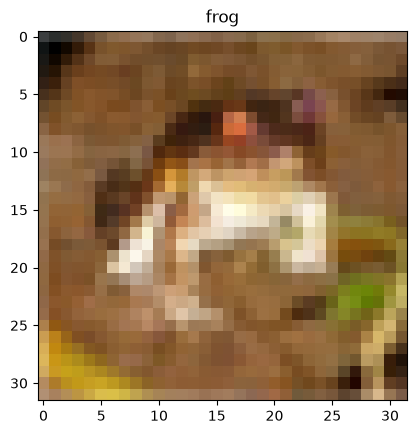

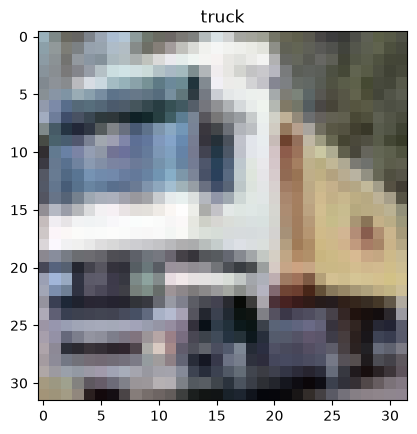

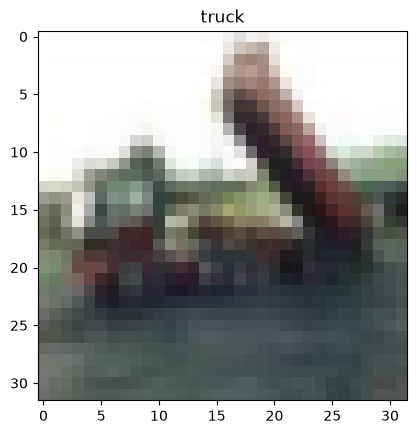

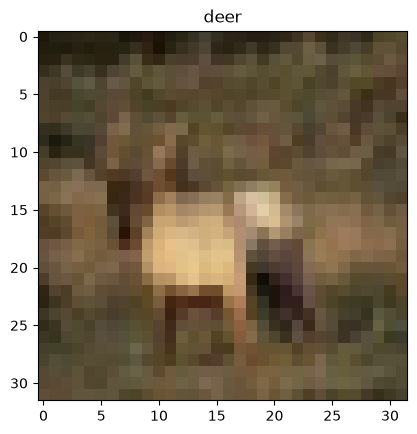

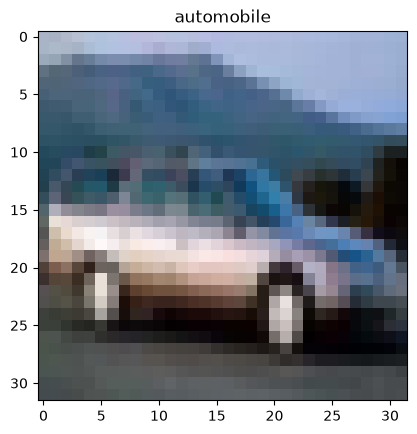

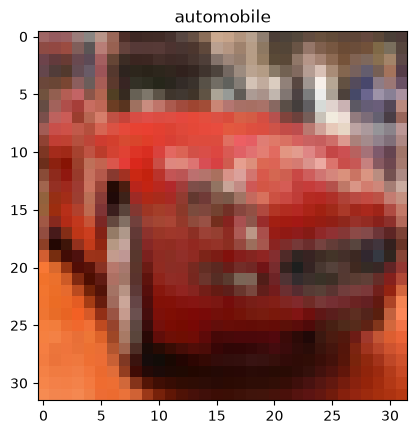

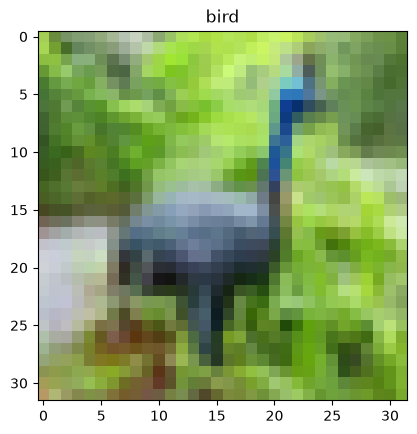

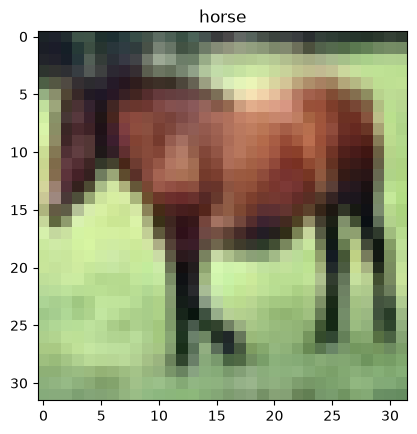

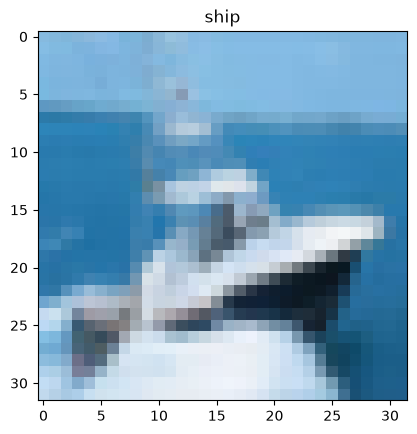

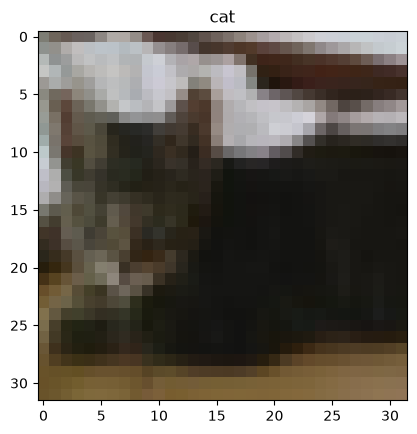

In [57]:

for i in range(10):
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.show()
    